# Imports

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Code

### Loading video and reading frames

In [22]:
video_path = "assets/book.mov"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Cannot open video file.")
    exit()

# Read one frame
ret, frame = cap.read()

# Check if the frame was successfully read
if not ret:
    print("End of video or error in reading frame.")

### Loading img

In [23]:
img1 = cv2.imread("assets/cv_cover.jpg", 0)  # Load book image
img2 = frame  #Load video frame

## 1.1 Finding best 50 matching points and draw them

In [24]:
def find_correspondences(img1, img2, n_matches):
    # Initialize SIFT detector
    sift = cv2.SIFT_create()

    #img1= cv2.cvtColor(img1,cv2.COLOR_BGR2GRAY)
    if len(img1.shape) > 2:
        gray1= cv2.cvtColor(img1,cv2.COLOR_BGR2GRAY)
    else:
        gray1=img1

    if len(img2.shape) > 2:
        gray2= cv2.cvtColor(img2,cv2.COLOR_BGR2GRAY)
    else:
        gray2=img2

    
    # Detect and compute keypoints and descriptors
    kp1, des1 = sift.detectAndCompute(gray1, None)
    kp2, des2 = sift.detectAndCompute(gray2, None)
    
    #img1=cv2.drawKeypoints(gray1,kp1,img1,flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    #cv2.imwrite('sift_keypoints1.jpg',img1)

    # Use BFMatcher with KNN
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)
    
    # Apply ratio test
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append([m])
    
    # Select best n matches
    n= n_matches
    good_matches = [m[0] for m in good_matches]
    good_matches = sorted(good_matches, key=lambda x: x.distance)[:n]
    good_matches = [[m] for m in good_matches]
    
    # Draw matches
    match_img = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good_matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return kp1, kp2, good_matches, match_img

### Finding matching points and drawing them

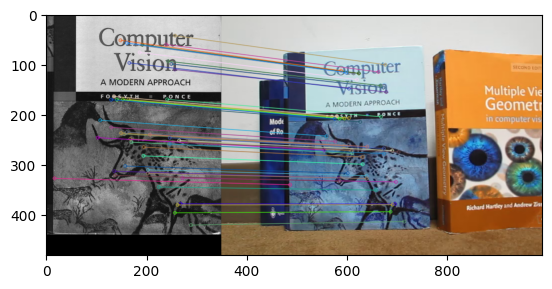

(<matplotlib.image.AxesImage at 0x1f5649b3450>, None)

In [25]:
kp1, kp2, matches, match_img = find_correspondences(img1, img2, 50)
plt.imshow(match_img), plt.show()

## 1.2 Computing homography matrix

In [26]:
def calc_homography(src_pts, dst_pts):
    
    # Convert points to homogeneous coordinates (3,1) shape
    '''def to_homogeneous(points):
        #print(points)
        return np.hstack((points, np.ones((points.shape[0], 1))))
    
    src_pts_h = to_homogeneous(src_pts)
    dst_pts_h = to_homogeneous(dst_pts)'''

    
    '''# Normalize points for numerical stability
    def normalize_points(points):
        mean = np.mean(points, axis=0)
        std_dev = np.std(points)
        transform = np.array([[1 / std_dev, 0, -mean[0] / std_dev],
                              [0, 1 / std_dev, -mean[1] / std_dev],
                              [0, 0, 1]])
        points_normalized = (transform @ points.T).T
        return points_normalized, transform

    src_pts_norm, T_src = normalize_points(src_pts_h)
    dst_pts_norm, T_dst = normalize_points(dst_pts_h)'''
    
    # Build the system of equations (Ax=b)
    A = []
    for (x, y), (x_prime, y_prime) in zip(src_pts, dst_pts):
        A.append([-x, -y, -1, 0, 0, 0, x * x_prime, y * x_prime, x_prime])
        A.append([0, 0, 0, -x, -y, -1, x * y_prime, y * y_prime, y_prime])
    A = np.array(A)

    # Solve using (SVD)
    _, _, V = np.linalg.svd(A)
    H_normalized = V[-1].reshape(3, 3)

    H_normalized /=  H_normalized[2,2] #Normalize using H(3,3) so that element 3,3 in homography matrix is 1
    
    return H_normalized


In [27]:
def compute_homography(kp1, kp2, matches):
    # Extract matched points and transform them to (2,1) shape
    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 2)
    
    # Compute homography
    H_norm = calc_homography(src_pts, dst_pts)
    return H_norm

In [28]:
def compute_homography_builtin(kp1, kp2, matches):
    # Extract matched points and transform them to (2,1) shape
    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 2)
    
    # Compute homography
    H, _ = cv2.findHomography(src_pts, dst_pts)
    return H

In [29]:
H_mat= compute_homography(kp1, kp2, [m[0] for m in matches])
H_mat2 = compute_homography_builtin(kp1, kp2, [m[0] for m in matches])

In [30]:
print("Homography matrix using function from scratch:")
print(H_mat)
print()
print("Homography matrix using build-in function:")
print(H_mat2)


Homography matrix using function from scratch:
[[ 7.73175746e-01  2.75722288e-03  1.19569964e+02]
 [-5.11103674e-02  7.78602152e-01  7.74981416e+01]
 [-9.11956120e-05 -7.43420639e-05  1.00000000e+00]]

Homography matrix using build-in function:
[[ 7.73918433e-01  2.98716605e-03  1.19494352e+02]
 [-5.06993013e-02  7.79124943e-01  7.74114010e+01]
 [-8.98341594e-05 -7.36718754e-05  1.00000000e+00]]


## 1.3 Calculating transformed book coordinates

In [31]:
#Getting corner coordinates in img 1
'''print(img1)
crop= img1[0:img1.shape[0], 0:img1.shape[1]]
cv2.imshow("Img", crop)
cv2.waitKey()
cv2.destroyAllWindows()'''

'print(img1)\ncrop= img1[0:img1.shape[0], 0:img1.shape[1]]\ncv2.imshow("Img", crop)\ncv2.waitKey()\ncv2.destroyAllWindows()'

In [32]:
corners = np.float32([[0, 0], [img1.shape[0], 0], [img1.shape[0], img1.shape[1]], [0, img1.shape[1]]]).reshape(-1, 1, 2)
print(corners.shape)
transformed_corners = cv2.perspectiveTransform(corners, H_mat)
print(transformed_corners.shape)

(4, 1, 2)
(4, 1, 2)


## 1.4-1.6 Overlaying frames of movie video onto the book video

In [33]:
#Cropping to same aspect ratio
def crop_to_match_aspect_ratio(img1, img2):
    # Get dimensions of both images
    h1, w1 = img1.shape[:2]  # img1 dimensions
    h2, w2 = img2.shape[:2]  # img2 dimensions

    # Calculate the aspect ratio of img1
    aspect_ratio_img1 = w1 / h1

    # Adjust img2 to match img1's aspect ratio
    if w2 / h2 > aspect_ratio_img1:
        # Crop width: img2 is too wide
        target_width = int(h2 * aspect_ratio_img1)
        crop_margin = (w2 - target_width) // 2
        img2_cropped = img2[:, crop_margin:crop_margin + target_width]
    else:
        # Crop height: img2 is too tall
        target_height = int(w2 / aspect_ratio_img1)
        crop_margin = (h2 - target_height) // 2
        img2_cropped = img2[crop_margin:crop_margin + target_height, :]

    return img2_cropped

We need a function that takes 3 inputs (book_img, book_frame, mov_frame).
It first calculates the homography matrix for that specific book_frame, then performs the operation to overlay the mov_frame onto the book_frame

In [34]:
def overlay_frame(book_img, book_frame, mov_frame):
    #Find keypoints matches between book_img and book_frame
    kp1, kp2, matches, _ = find_correspondences(book_img, book_frame, 30) #We don't need the matches img for this part and we can choose how many correspondences to return

    #Use n best matches to compute homogprahy matrix
    H_mat= compute_homography(kp1, kp2, [m[0] for m in matches])

    #Find the corners of the book_img in this specific book_frame
    h, w= book_img.shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    transformed_corners = cv2.perspectiveTransform(corners, H_mat)

    #Crop mov_frame to be of same aspect ratio as book_img then resize it for homography transformation
    mov_frame_cropped= crop_to_match_aspect_ratio(book_img, mov_frame)
    mov_frame_resized = cv2.resize(mov_frame_cropped, (w, h))

    #Getting dimensions of book_frame
    h, w, _= book_frame.shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)

    #Warp mov_frame to match the book in book_frame using homography matrix
    warped_mov_frame = cv2.warpPerspective(mov_frame_resized, H_mat, (w, h))
    

    # Create a mask for blending the warped mov_frame and book_frame
    mask = np.zeros_like(book_frame, dtype=np.uint8)
    transformed_corners = np.clip(transformed_corners, 0, (w, h))
    cv2.fillConvexPoly(mask, np.int32(transformed_corners), (255, 255, 255))

    # Invert the mask
    mask_inv = cv2.bitwise_not(mask)

    # Combine the warped AR content and the book frame
    book_frame_bg = cv2.bitwise_and(book_frame, mask_inv)
    mov_frame_fg = cv2.bitwise_and(warped_mov_frame, mask)
    result_frame = cv2.add(book_frame_bg, mov_frame_fg)

    return result_frame

### Overlaying first frame of mov_video onto first frame of book_video

In [35]:
book= "assets/book.mov"
mov= "assets/ar_source.mov"
op = "outputs/ar_output.avi"

In [36]:
book_vid= cv2.VideoCapture(book)
mov_vid= cv2.VideoCapture(mov)

In [37]:
_, book_frame = book_vid.read()
_, mov_frame = mov_vid.read()

In [38]:
a= overlay_frame(img1, book_frame, mov_frame)
cv2.imshow('First frame',a)
cv2.waitKey()
cv2.destroyAllWindows()

### Overlaying all frames of mov_video onto all frames of book_video 

In [39]:
def ar_video(book_img, book_video_path, mov_video_path, op_path):
    book_vid= cv2.VideoCapture(book_video_path)
    mov_vid= cv2.VideoCapture(mov_video_path)
    op=[]

    #Reading first frame of both videos
    _, book_frame = book_vid.read()
    _, mov_frame = mov_vid.read()

    #Videowriter for output to file
    h, w, _ = book_frame.shape
    fourcc = cv2.VideoWriter_fourcc(*'XVID')  # Choose codec (e.g., XVID, DIVX, MJPG)
    out = cv2.VideoWriter(op_path, fourcc, 30.0, (w, h))  # Assuming 30 FPS

    while book_frame is not None and mov_frame is not None:

        result_frame = overlay_frame(book_img, book_frame, mov_frame)
        cv2.imshow('AR Video Frame', result_frame)

        out.write(result_frame)

        key = cv2.waitKey(1)  # Wait for 1ms for a key press
        if key == ord('q'):
            break  # Exit the loop if 'q' is pressed

        op.append(overlay_frame(book_img, book_frame, mov_frame))

        #Get next frame
        _, book_frame = book_vid.read()
        _, mov_frame = mov_vid.read()

    book_vid.release()
    mov_vid.release()
    out.release()
    cv2.destroyAllWindows()
    

In [40]:
ar_video(img1, book, mov, op)